# Data Engineering & Visualization – Milestone 1
## Member 2 – Transportation Dataset (SIRTA): Overview, EDA & Pre-Integration Cleaning

**Course:** Data Engineering and Visualization, Winter 2026 – GIU
**Team member:** Member 2 (Mariam) – Transportation dataset
**Output of this notebook:** `transport_clean_row_level.csv` (clean crash records) and `transport_clean.csv` (aggregated to **ZIP code × year**, ready for Member 3 to integrate with the housing dataset).

**Contents**
1. Dataset overview and reasoning for selection
2. Loading the data (with justification for any sampling)
3. Exploratory Data Analysis (EDA)
4. Pre-integration cleaning (missing values, duplicates, inconsistencies, formats, outliers)
5. Validation of cleaning (before vs. after)
6. Aggregation to the integration level (ZIP code × year) – the data contract
7. Research questions and visualizations (Member 2)
8. Prompts used, dataset links, and contribution statement

## 1. Dataset overview and reasoning for selection

| Item | Value |
|---|---|
| Dataset | **Serious Injury Response, Tracking & Analysis Program (SIRTA)** – catalog ID **T4** |
| Domain | Transportation |
| Publisher | NYC Department of Transportation (DOT) |
| Dataset ID | `xeqp-qz8h` |
| Link | https://data.cityofnewyork.us/Transportation/Serious-Injury-Response-Tracking-Analysis-Program-/xeqp-qz8h |
| Data dictionary | `SIRTA_Data_Dictionary.xlsx` (provided by the course) |
| Unit of analysis (row) | One serious vehicular crash that DOT analyzed and reported at a specific location |
| Rows / columns | 13,754 rows x 23 columns in the downloaded CSV (requirement: at least 9 columns) |
| Period covered | 01/01/2022 - 12/31/2024 (date format MM/DD/YYYY in the CSV export) |
| Temporal attributes | `Crash Date` (YYYY-MM-DD), `Crash Time` (HH:MM) |
| Geographic attributes | `Crash Borough`, `ZipCode`, `Latitude`/`Longitude`, `Community Board`, `Council District`, `NTA 2020`, `Census Tract 2020`, `BIN`, `BBL`, `Crash Police Precinct` |
| Update frequency | Quarterly publication (Local Law 49 of 2021) |

**Columns (from the data dictionary / portal):** Collision ID, Crash Date, Crash Time, Crash Police Precinct, Crash Borough, Total Non-Severe Injuries, Total Severe Injuries, Total Fatalities, Latitude, Longitude, On Street, Cross Street, Address, Highway Reference Marker, ZipCode, Similar Fatalities & Severe Injuries (3Y Lookback), Similar Fatalities & All Injuries (3Y Lookback), Community Board, Council District, BIN, BBL, Census Tract 2020, NTA 2020.

**Why this dataset?**
- It is **in the course catalog (T4)**, so no extra feasibility check is required.
- It has **ZIP code, borough and a crash date**, which are exactly the attributes needed to link it to housing data (permits / job filings) at **ZIP code × year** level.
- It carries **severity information** (severe injuries, fatalities), so we can ask richer questions than simple counts, e.g. whether street danger changes around areas of new residential development.

**Known issues (from the data dictionary, to be verified in the EDA):**
- Data comes directly from NYPD's FORMS system; **blank values mean the data was not recorded**, not zero.
- Only crashes classified as **severe ("A" injuries)** by the NYS DMV formula are included, so this is **not all crashes** – conclusions concern *serious* crashes only.
- Severity classification can lag by more than a year, so the most recent period may be incomplete.

**Granularity / aggregation plan.** The housing dataset has building-level records, while SIRTA has crash-level records. Neither will be joined record-to-record. Both are aggregated to **ZIP code × year** (a common geographic and temporal level that both datasets share). ZIP is fine-grained enough to see neighborhood patterns and coarse enough that each cell contains enough crashes/filings to be meaningful.

## 2. Loading the data

The dataset is moderate in size, so we try to download it **in full** from the NYC Open Data API using `$limit` (the API returns only 1,000 rows by default). If the download is blocked (e.g. no connection to the portal), the notebook falls back to a CSV exported manually from the portal (**Export → CSV**) and saved next to the notebook.

**Configuration (agree these values with the team):**
- `YEAR_MIN` / `YEAR_MAX`: the common time window with the housing dataset. The downloaded file covers **2022-01-01 to 2026-06-30**; **2026 is only half a year**, so the default window is **2022-2025 (four complete years)**. The window must be confirmed with the team once the housing dataset is fixed. Set a value to `None` to keep all years.

In [1]:
import os
import re
import warnings
from urllib.parse import urlencode

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neighbors import NearestNeighbors

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 70   # lighter saved plots (small notebook file)
pd.set_option("display.max_columns", 50)

# ----------------------------- configuration -----------------------------
TRANSPORT_ID = "xeqp-qz8h"                       # SIRTA dataset ID (T4)
API_URL = "https://data.cityofnewyork.us/resource/{}.csv"
LOCAL_CSV = "xeqp-qz8h.csv"                      # fallback: manual export from the portal
YEAR_MIN, YEAR_MAX = 2022, 2025                  # complete years only; adjust if the team agrees on another window with the housing data
OUTPUT_ROW_LEVEL = "transport_clean_row_level.csv"
OUTPUT_AGGREGATED = "transport_clean.csv"

In [2]:
def load_sirta(dataset_id=TRANSPORT_ID, local_csv=LOCAL_CSV):
    """Load SIRTA from the NYC Open Data API; fall back to a local CSV export."""
    params = {"$limit": 1_000_000, "$order": ":id"}   # $order keeps the download repeatable
    url = API_URL.format(dataset_id) + "?" + urlencode(params)
    try:
        frame = pd.read_csv(url, low_memory=False)
        print(f"Loaded {len(frame):,} rows from the API.")
    except Exception as error:                          # network blocked, timeout, ...
        print(f"API download failed ({type(error).__name__}); using local file '{local_csv}'.")
        frame = pd.read_csv(local_csv, low_memory=False)
        print(f"Loaded {len(frame):,} rows from the local CSV.")
    return frame

df_raw = load_sirta()
df = df_raw.copy()          # keep the raw frame untouched for before/after comparison
df.head()

API download failed (URLError); using local file 'xeqp-qz8h.csv'.
Loaded 13,754 rows from the local CSV.


,Collision ID,Crash Date,Crash Time,Crash Police Precinct,Crash Borough,Total Non-Severe Injuries,Total Severe Injuries,Total Fatalities,Latitude,Longitude,On Street,Cross Street,Address,Highway Reference Marker,ZipCode,Similar Fatalities & Severe Injuries (3Y Lookback),Similar Fatalities & All Injuries (3Y Lookback),Community Board,Council District,Building Identification Number (BIN),Borough Block Lot (BBL),Census Tract (2020),Neighborhood Tabulation Area (NTA) (2020)
0,4492364.0,01/01/2022,01:28,46.0,Bronx,1.0,1.0,0.0,40.858707,-73.90370,JEROME AVENUE,EAST 183 STREET,NaN,NaN,NaN,0.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN
1,4491159.0,01/01/2022,04:33,46.0,Bronx,0.0,1.0,0.0,NaN,NaN,JEROME AVENUE,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
2,4491487.0,01/01/2022,05:55,47.0,Bronx,0.0,1.0,0.0,40.871550,-73.86428,NaN,NaN,3207 WALLACE AVENUE,NaN,NaN,0.0,0.0,212.0,12.0,2056281.0,2.045980e+09,372.0,BX1201
3,4491223.0,01/01/2022,10:42,43.0,Bronx,0.0,1.0,0.0,40.823673,-73.87233,BRONX RIVER PARKWAY,NaN,NaN,907HX1M11001,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
4,4491418.0,01/01/2022,20:55,49.0,Bronx,0.0,1.0,0.0,40.863945,-73.86452,BOSTON ROAD,WALLACE AVENUE,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
def standardize_column_names(frame):
    """Lowercase snake_case names so the API and the portal CSV export look identical."""
    frame = frame.copy()
    frame.columns = (frame.columns.str.strip().str.lower()
                     .str.replace(r"[^0-9a-z]+", "_", regex=True).str.strip("_"))
    return frame

df = standardize_column_names(df)
print(df.columns.tolist())

['collision_id', 'crash_date', 'crash_time', 'crash_police_precinct', 'crash_borough', 'total_non_severe_injuries', 'total_severe_injuries', 'total_fatalities', 'latitude', 'longitude', 'on_street', 'cross_street', 'address', 'highway_reference_marker', 'zipcode', 'similar_fatalities_severe_injuries_3y_lookback', 'similar_fatalities_all_injuries_3y_lookback', 'community_board', 'council_district', 'building_identification_number_bin', 'borough_block_lot_bbl', 'census_tract_2020', 'neighborhood_tabulation_area_nta_2020']


In [4]:
def find_column(frame, *keywords):
    """Return the first column whose name contains ALL keywords (robust to API/CSV naming differences)."""
    for column in frame.columns:
        if all(keyword in column for keyword in keywords):
            return column
    raise KeyError(f"No column contains {keywords}. Available: {frame.columns.tolist()}")

def parse_crash_dates(series):
    """Parse dates from either the portal CSV (MM/DD/YYYY) or the API (ISO timestamp)."""
    parsed = pd.to_datetime(series, format="%m/%d/%Y", errors="coerce")
    leftover = parsed.isna() & series.notna()
    if leftover.any():
        parsed[leftover] = pd.to_datetime(series[leftover], errors="coerce")
    return parsed

# Map the logical names we use below to the real column names in the downloaded file.
COL = {
    "collision_id": next(c for c in df.columns if "collision" in c or c.endswith("crash_id")),   # portal CSV: collision_id | API: open_data_crash_id
    "crash_date":   find_column(df, "crash", "date"),
    "crash_time":   find_column(df, "crash", "time"),
    "precinct":     find_column(df, "precinct"),
    "borough":      find_column(df, "borough") if any("borough" in c and "block" not in c for c in df.columns) else None,
    "non_severe":   find_column(df, "non", "severe"),
    "fatalities":   find_column(df, "fatalit") if not any(c.startswith("total_fatalit") for c in df.columns) else "total_fatalities",
    "latitude":     find_column(df, "latitude"),
    "longitude":    find_column(df, "longitude"),
    "zip":          find_column(df, "zip"),
}
# 'total_severe_injuries' must not be confused with 'total_non_severe_injuries'
COL["severe"] = next(c for c in df.columns if "severe" in c and "non" not in c and c.startswith("total"))
COL["borough"] = next(c for c in df.columns if "borough" in c and "block" not in c)
COL["fatalities"] = next(c for c in df.columns if c.startswith("total_fatalit"))
print(COL)

{'collision_id': 'collision_id', 'crash_date': 'crash_date', 'crash_time': 'crash_time', 'precinct': 'crash_police_precinct', 'borough': 'crash_borough', 'non_severe': 'total_non_severe_injuries', 'fatalities': 'total_fatalities', 'latitude': 'latitude', 'longitude': 'longitude', 'zip': 'zipcode', 'severe': 'total_severe_injuries'}


## 3. Exploratory Data Analysis (EDA)

Goal: understand the structure of the data, find quality problems, and see the main patterns *before* cleaning, so every cleaning decision in Section 4 is justified by evidence.

### 3.1 Structure: shape, data types, memory

In [5]:
print("Rows, columns:", df.shape)
print("Required: at least 9 columns ->", "OK" if df.shape[1] >= 9 else "NOT OK")
summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "n_unique": df.nunique(),
})
summary

Rows, columns: (13754, 23)
Required: at least 9 columns -> OK


,dtype,non_null,n_unique
collision_id,float64,13310,13309
crash_date,str,13310,1641
crash_time,str,13310,1728
crash_police_precinct,float64,13310,78
crash_borough,str,13255,5
total_non_severe_injuries,float64,13310,16
total_severe_injuries,float64,13310,8
total_fatalities,float64,13310,6
latitude,float64,10868,8570
longitude,float64,10868,8219


### 3.2 Missing values
The data dictionary warns that blanks mean *not recorded*. We quantify them per column to decide which columns are usable, which can be repaired, and which should be dropped.

,missing_pct,missing_count
highway_reference_marker,92.351316,12702
address,81.263632,11177
building_identification_number_bin,79.736804,10967
borough_block_lot_bbl,79.736804,10967
census_tract_2020,71.877272,9886
neighborhood_tabulation_area_nta_2020,71.877272,9886
council_district,71.855460,9883
community_board,71.855460,9883
zipcode,41.311618,5682
cross_street,41.020794,5642


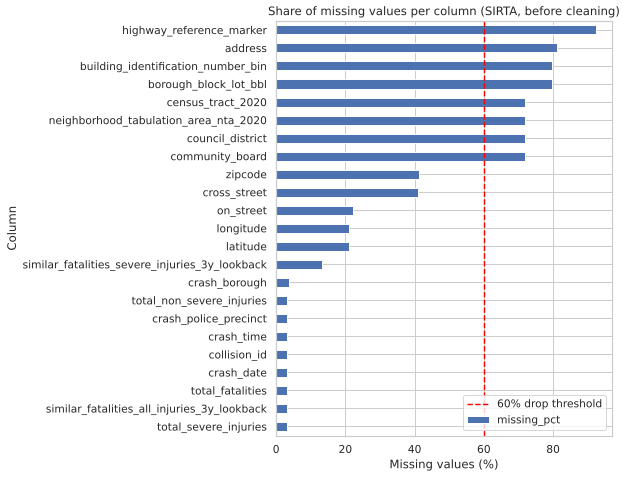

In [6]:
missing = (df.isna().mean() * 100).sort_values(ascending=False).rename("missing_pct").to_frame()
missing["missing_count"] = df.isna().sum()
display(missing)

fig, ax = plt.subplots(figsize=(9, 7))
missing["missing_pct"].sort_values().plot.barh(ax=ax, color="#4C72B0")
ax.axvline(60, color="red", ls="--", label="60% drop threshold")
ax.set_title("Share of missing values per column (SIRTA, before cleaning)")
ax.set_xlabel("Missing values (%)")
ax.set_ylabel("Column")
ax.legend()
plt.tight_layout()
plt.show()

### 3.3 Descriptive statistics

In [7]:
numeric_cols = df.select_dtypes(include="number").columns.tolist()
display(df[numeric_cols].describe().T)
print("\nCategorical / text columns:")
display(df.select_dtypes(exclude="number").describe().T)

,count,mean,std,min,25%,50%,75%,max
collision_id,13310.0,7.271533e+06,1.128930e+07,2.126022e+06,4.612503e+06,4.718838e+06,4.814223e+06,1.213261e+08
crash_police_precinct,13310.0,6.783787e+01,3.468395e+01,1.000000e+00,4.200000e+01,6.800000e+01,1.040000e+02,1.230000e+02
total_non_severe_injuries,13310.0,2.704733e-01,8.360310e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.900000e+01
total_severe_injuries,13310.0,1.011495e+00,4.515143e-01,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,7.000000e+00
total_fatalities,13310.0,8.279489e-02,2.943044e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,5.000000e+00
latitude,10868.0,4.073064e+01,8.337807e-02,4.049967e+01,4.066785e+01,4.072671e+01,4.080066e+01,4.091247e+01
longitude,10868.0,-7.392154e+01,8.192903e-02,-7.424857e+01,-7.396879e+01,-7.392369e+01,-7.387474e+01,-7.370060e+01
zipcode,8072.0,1.081959e+04,5.437498e+02,1.000000e+04,1.031200e+04,1.120400e+04,1.123500e+04,1.169400e+04
similar_fatalities_severe_injuries_3y_lookback,11917.0,9.549383e-02,4.217294e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,9.000000e+00
similar_fatalities_all_injuries_3y_lookback,13310.0,1.544328e+00,5.857394e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,2.960000e+02



Categorical / text columns:


,count,unique,top,freq
crash_date,13310,1641,05/21/2022,22
crash_time,13310,1728,00:00,186
crash_borough,13255,5,Brooklyn,3954
on_street,10718,2952,BROADWAY,167
cross_street,8112,3380,BROADWAY,83
address,2577,2526,101 EAST DRIVE,3
highway_reference_marker,1052,825,907LX4M12071,5
neighborhood_tabulation_area_nta_2020,3868,224,MN0502,89


### 3.4 Duplicates

In [8]:
print("Fully duplicated rows:", df.duplicated().sum())
print("Duplicated CollisionIDs:", df.duplicated(subset=[COL['collision_id']]).sum())

Fully duplicated rows: 3
Duplicated CollisionIDs: 444


### 3.5 Inconsistencies in key fields
We inspect the categorical/geographic fields we plan to use as integration keys (borough and ZIP) and the date/time fields.

In [9]:
print("Borough values (raw):")
print(df[COL["borough"]].value_counts(dropna=False))
print("\nZIP code - sample of raw values and dtype:", df[COL["zip"]].dtype)
print(df[COL["zip"]].dropna().astype(str).sample(10, random_state=1).tolist())
print("\nCrash date sample:", df[COL["crash_date"]].dropna().astype(str).head(3).tolist())
print("Crash time sample:", df[COL["crash_time"]].dropna().astype(str).head(3).tolist())

Borough values (raw):
crash_borough
Brooklyn         3954
Queens           3282
Manhattan        2733
Bronx            2617
Staten Island     669
NaN               499
Name: count, dtype: int64

ZIP code - sample of raw values and dtype: float64
['11205.0', '11385.0', '11233.0', '10462.0', '11236.0', '10301.0', '10001.0', '11358.0', '10473.0', '11213.0']

Crash date sample: ['01/01/2022', '01/01/2022', '01/01/2022']
Crash time sample: ['01:28', '04:33', '05:55']


### 3.6 Initial plots: what does the data look like?

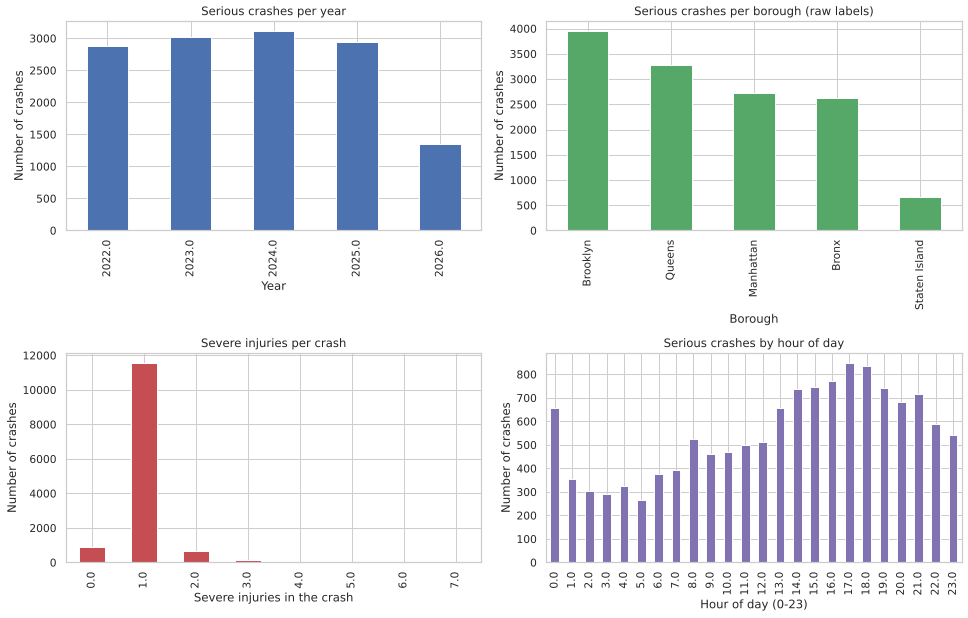

In [10]:
raw_dates = parse_crash_dates(df[COL["crash_date"]])

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# (a) crashes per year
raw_dates.dt.year.value_counts().sort_index().plot.bar(ax=axes[0, 0], color="#4C72B0")
axes[0, 0].set_title("Serious crashes per year")
axes[0, 0].set_xlabel("Year"); axes[0, 0].set_ylabel("Number of crashes")

# (b) crashes per borough
df[COL["borough"]].value_counts().plot.bar(ax=axes[0, 1], color="#55A868")
axes[0, 1].set_title("Serious crashes per borough (raw labels)")
axes[0, 1].set_xlabel("Borough"); axes[0, 1].set_ylabel("Number of crashes")

# (c) distribution of severe injuries per crash
df[COL["severe"]].value_counts().sort_index().head(15).plot.bar(ax=axes[1, 0], color="#C44E52")
axes[1, 0].set_title("Severe injuries per crash")
axes[1, 0].set_xlabel("Severe injuries in the crash"); axes[1, 0].set_ylabel("Number of crashes")

# (d) crashes per hour of day
hours = pd.to_datetime(df[COL["crash_time"]].astype(str), format="%H:%M", errors="coerce").dt.hour
hours.value_counts().sort_index().plot.bar(ax=axes[1, 1], color="#8172B2")
axes[1, 1].set_title("Serious crashes by hour of day")
axes[1, 1].set_xlabel("Hour of day (0-23)"); axes[1, 1].set_ylabel("Number of crashes")

plt.tight_layout()
plt.show()

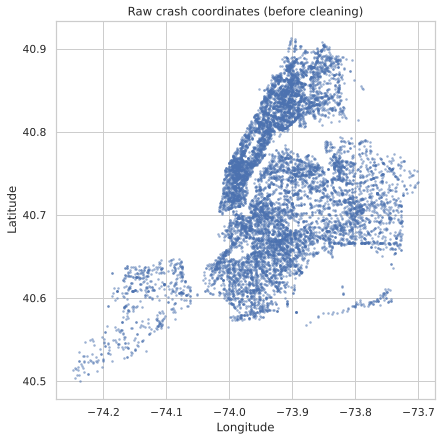

In [11]:
# Geographic sanity check on the raw coordinates (outliers appear as points far from NYC)
fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(pd.to_numeric(df[COL["longitude"]], errors="coerce"),
           pd.to_numeric(df[COL["latitude"]], errors="coerce"), s=3, alpha=0.4)
ax.set_title("Raw crash coordinates (before cleaning)")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
plt.show()

**EDA take-aways (from the downloaded file: 13,754 rows x 23 columns):**
- **Empty rows:** 444 rows (3.2 %) are completely blank (no Collision ID, date or counts) - removed in 4.0.
- **Missing values:** `highway_reference_marker` (92 %), `address` (81 %), BIN/BBL (80 %), and `community_board`, `council_district`, census tract and NTA (72 %) are too sparse to use. **ZIP is missing in 41 %** and coordinates in 21 % of rows, so the integration key needs repair (4.4).
- **Formats:** dates are `MM/DD/YYYY` text; ZIP is read as float (`11205.0`); borough labels are title-case and ~4 % are missing.
- **Invalid values:** 44 ZIP values equal `10000`, which is a placeholder, not a real NYC ZIP.
- **Time coverage:** 2022-01-01 to 2026-06-30; **2026 is incomplete** (six months).
- **Severity:** most crashes (~84 %) have exactly one severe injury; about 7 % involve a fatality.

## 4. Pre-integration cleaning

Each step states **what** we do, **why**, and **which alternative** we considered.

### 4.0 Remove completely empty rows
The EDA shows about 3% of the rows have **no Collision ID, no date and no severity counts** (every key field is blank). They carry no information, are not crashes, and would all be treated as one "duplicate" in the next step, so we remove them first.

In [12]:
empty_rows = df[COL["collision_id"]].isna() & df[COL["crash_date"]].isna()
print(f"Completely empty rows removed: {empty_rows.sum():,} ({empty_rows.mean():.1%})")
df = df.loc[~empty_rows].copy()

Completely empty rows removed: 444 (3.2%)


### 4.1 Remove duplicates
**Decision:** drop exact duplicate rows, then keep one row per `CollisionID`.
**Why:** one row = one crash, so a repeated `CollisionID` double-counts the crash and would inflate the aggregated crash counts that we later correlate with housing.
**Alternative:** keep the most severe duplicate. Because duplicates should be identical copies, keeping the first is equivalent and simpler.

In [13]:
def remove_duplicates(frame, id_col):
    before = len(frame)
    frame = frame.drop_duplicates()
    frame = frame.drop_duplicates(subset=[id_col], keep="first")
    print(f"Removed {before - len(frame):,} duplicate rows ({before:,} -> {len(frame):,}).")
    return frame

df = remove_duplicates(df, COL["collision_id"])

Removed 1 duplicate rows (13,310 -> 13,309).


### 4.2 Standardize formats (dates, strings, categories, geographic identifiers)
- **Dates:** parse `crash_date` to `datetime`; derive `year`, `month`, `day_of_week`. Invalid or impossible dates (unparseable or in the future) are dropped because the year is part of our integration key.
- **Time:** parse `crash_time` (HH:MM) to hour and a `time_of_day` category (night / morning / afternoon / evening).
- **Borough:** strip whitespace and convert to UPPERCASE (`BROOKLYN`, `BRONX`, `MANHATTAN`, `QUEENS`, `STATEN ISLAND`) to match the agreed data contract.
- **ZIP code:** store as a **5-digit string** (never a number, otherwise leading zeros/`.0` break the join).
- **Counts:** injuries/fatalities converted to integers; negative values are invalid.
- **Column names:** lowercase snake_case (done in Section 2).

In [14]:
VALID_BOROUGHS = {"BRONX", "BROOKLYN", "MANHATTAN", "QUEENS", "STATEN ISLAND"}

def standardize_formats(frame, col):
    frame = frame.copy()

    # --- dates and time
    frame["crash_date"] = parse_crash_dates(frame[col["crash_date"]])
    frame["year"] = frame["crash_date"].dt.year
    frame["month"] = frame["crash_date"].dt.month
    frame["day_of_week"] = frame["crash_date"].dt.day_name()
    parsed_time = pd.to_datetime(frame[col["crash_time"]].astype(str).str.strip(), format="%H:%M", errors="coerce")
    frame["crash_hour"] = parsed_time.dt.hour
    frame["time_of_day"] = pd.cut(frame["crash_hour"], bins=[-1, 5, 11, 17, 21, 24],
                                  labels=["night", "morning", "afternoon", "evening", "night_late"])
    frame["time_of_day"] = frame["time_of_day"].astype(str).replace({"night_late": "night", "nan": np.nan})

    # --- borough: trim + uppercase
    frame["borough"] = frame[col["borough"]].astype("string").str.strip().str.upper()

    # --- ZIP: 5-digit string; remove '.0' left by float parsing; non 5-digit values -> NaN
    zip_text = (frame[col["zip"]].astype("string").str.strip()
                .str.replace(r"\.0$", "", regex=True).str.extract(r"^(\d{5})", expand=False))
    frame["zip_code"] = zip_text

    # --- numeric columns
    for name in ("severe", "non_severe", "fatalities"):
        frame[f"{name}_count"] = pd.to_numeric(frame[col[name]], errors="coerce")
    frame["latitude"] = pd.to_numeric(frame[col["latitude"]], errors="coerce")
    frame["longitude"] = pd.to_numeric(frame[col["longitude"]], errors="coerce")
    return frame

df = standardize_formats(df, COL)
df[["crash_date", "year", "crash_hour", "time_of_day", "borough", "zip_code",
    "severe_count", "non_severe_count", "fatalities_count"]].head()

,crash_date,year,crash_hour,time_of_day,borough,zip_code,severe_count,non_severe_count,fatalities_count
0,2022-01-01,2022,1,night,BRONX,<NA>,1.0,1.0,0.0
1,2022-01-01,2022,4,night,BRONX,<NA>,1.0,0.0,0.0
2,2022-01-01,2022,5,night,BRONX,<NA>,1.0,0.0,0.0
3,2022-01-01,2022,10,morning,BRONX,<NA>,1.0,0.0,0.0
4,2022-01-01,2022,20,evening,BRONX,<NA>,1.0,0.0,0.0


### 4.3 Check inconsistent data (domain rules)
Rules applied:
1. `crash_date` must be a valid date and **not in the future**.
2. Borough must be one of the 5 NYC boroughs.
3. Injury and fatality counts must be **non-negative**.
4. Coordinates must lie inside a bounding box around New York City (lat 40.45–40.95, lon −74.30 – −73.65); anything else is a data-entry error.
5. ZIP codes must be inside NYC ZIP ranges (100xx–104xx, 110xx–116xx) – this catches typos such as `00000` or ZIPs outside the city.
6. **Borough–ZIP consistency:** a ZIP should map to one borough; where it maps to several we keep the dominant borough (the mode) for the ZIP.

**Decision:** invalid values are set to missing (not silently kept) and then handled by the missing-value strategy in 4.4. Rows without a usable date are dropped (the year is required).

In [15]:
def apply_domain_rules(frame):
    frame = frame.copy()
    report = {}

    # Rule 1: dates
    bad_date = frame["crash_date"].isna() | (frame["crash_date"] > pd.Timestamp.today())
    report["invalid/future date"] = int(bad_date.sum())
    frame = frame.loc[~bad_date].copy()

    # Rule 2: boroughs
    bad_borough = ~frame["borough"].isin(VALID_BOROUGHS) & frame["borough"].notna()
    report["invalid borough label -> NaN"] = int(bad_borough.sum())
    frame.loc[bad_borough, "borough"] = np.nan

    # Rule 3: negative counts
    for name in ("severe_count", "non_severe_count", "fatalities_count"):
        negative = frame[name] < 0
        report[f"negative {name} -> NaN"] = int(negative.sum())
        frame.loc[negative, name] = np.nan

    # Rule 4: coordinates inside the NYC bounding box
    outside = ~(frame["latitude"].between(40.45, 40.95) & frame["longitude"].between(-74.30, -73.65))
    outside &= frame["latitude"].notna() | frame["longitude"].notna()
    report["coordinates outside NYC -> NaN"] = int(outside.sum())
    frame.loc[outside, ["latitude", "longitude"]] = np.nan

    # Rule 5: NYC ZIP ranges
    zip_number = pd.to_numeric(frame["zip_code"], errors="coerce")
    valid_zip = zip_number.between(10001, 10499) | zip_number.between(11001, 11699)
    bad_zip = frame["zip_code"].notna() & ~valid_zip
    report["ZIP outside NYC ranges -> NaN"] = int(bad_zip.sum())
    frame.loc[bad_zip, "zip_code"] = np.nan

    print(pd.Series(report).to_string())
    return frame

df = apply_domain_rules(df)

invalid/future date                  0
invalid borough label -> NaN         0
negative severe_count -> NaN         0
negative non_severe_count -> NaN     0
negative fatalities_count -> NaN     0
coordinates outside NYC -> NaN       0
ZIP outside NYC ranges -> NaN       44


In [16]:
# Rule 6: borough-ZIP consistency. Use the dominant borough of each ZIP.
zip_to_borough = (df.dropna(subset=["zip_code", "borough"])
                    .groupby("zip_code")["borough"].agg(lambda s: s.mode().iloc[0]))
ambiguous = (df.dropna(subset=["zip_code", "borough"]).groupby("zip_code")["borough"].nunique() > 1).sum()
print(f"ZIP codes appearing in more than one borough label: {ambiguous}")

df["borough"] = df["zip_code"].map(zip_to_borough).fillna(df["borough"])

ZIP codes appearing in more than one borough label: 2


### 4.4 Handle missing values (justify drop vs. impute)

**Column level**
- Columns with **> 60 % missing** and no role in the analysis (e.g. highway reference marker, BIN, BBL, address) are **dropped**. Imputing them would invent information, and they are not needed for ZIP × year aggregation.
- Columns that are always needed (`crash_date`, severity counts) are never imputed; rows missing them are dropped.

**Row level – ZIP code (our integration key)**
- The dictionary says a missing ZIP means *not recorded*. If the crash still has valid coordinates, the ZIP is **recovered from the nearest crash that has a ZIP** (1-nearest-neighbour on latitude/longitude) – but only if that neighbour is very close (≈ 500 m) so we do not assign a wrong ZIP.
- Rows with **no ZIP and no usable coordinates** are **dropped**: without the key they cannot take part in the ZIP × year integration. The number dropped is reported.

**Alternatives considered:** (a) impute ZIP with the most frequent ZIP of the borough – rejected because it would bias counts toward one ZIP; (b) keep rows with missing ZIP and group them as "UNKNOWN" – rejected because they could never be joined to housing data.

**Count columns:** a blank means *not recorded*, not zero, so we never fill missing counts with 0. Rows with a missing severe-injury count are dropped; gaps in the secondary counts (non-severe, fatalities) stay as missing and are skipped by the aggregation.

In [17]:
MISSING_DROP_THRESHOLD = 0.60

def drop_sparse_columns(frame, threshold=MISSING_DROP_THRESHOLD, protect=()):
    share = frame.isna().mean()
    to_drop = [c for c in share[share > threshold].index if c not in protect]
    print("Dropping columns with >60% missing:", to_drop)
    return frame.drop(columns=to_drop)

PROTECTED = ["crash_date", "year", "month", "borough", "zip_code", "latitude", "longitude",
             "severe_count", "non_severe_count", "fatalities_count", "crash_hour", "time_of_day", "day_of_week"]
df = drop_sparse_columns(df, protect=PROTECTED)

Dropping columns with >60% missing: ['address', 'highway_reference_marker', 'community_board', 'council_district', 'building_identification_number_bin', 'borough_block_lot_bbl', 'census_tract_2020', 'neighborhood_tabulation_area_nta_2020']


In [18]:
def impute_zip_from_nearest_crash(frame, max_distance_deg=0.005):
    """Fill a missing ZIP with the ZIP of the nearest crash (same file) that has one.
    0.005 degrees is roughly 500 m in NYC; farther neighbours are not trusted."""
    frame = frame.copy()
    known = frame.dropna(subset=["zip_code", "latitude", "longitude"])
    target = frame[frame["zip_code"].isna() & frame["latitude"].notna() & frame["longitude"].notna()]
    print(f"Missing ZIP: {frame['zip_code'].isna().sum():,} | recoverable via coordinates: {len(target):,}")
    if len(target) == 0 or len(known) == 0:
        return frame, 0
    nn = NearestNeighbors(n_neighbors=1).fit(known[["latitude", "longitude"]])
    distance, index = nn.kneighbors(target[["latitude", "longitude"]])
    close_enough = distance[:, 0] <= max_distance_deg
    filled_index = target.index[close_enough]
    frame.loc[filled_index, "zip_code"] = known["zip_code"].to_numpy()[index[close_enough, 0]]
    # borough follows the (new) ZIP
    frame.loc[filled_index, "borough"] = frame.loc[filled_index, "zip_code"].map(zip_to_borough).fillna(frame.loc[filled_index, "borough"])
    print(f"ZIP imputed for {len(filled_index):,} rows.")
    return frame, len(filled_index)

df, n_zip_imputed = impute_zip_from_nearest_crash(df)

# Drop rows that still lack the integration key or the core measures
before = len(df)
df = df.dropna(subset=["zip_code", "severe_count"]).copy()
print(f"Dropped {before - len(df):,} rows without ZIP or severe-injury count ({before:,} -> {len(df):,}).")

# Remaining numeric gaps in the secondary counts: blank = 'not recorded', so keep them as NaN (not 0)
# and let the aggregation skip them; they are reported rather than invented.
print(df[["non_severe_count", "fatalities_count", "borough", "crash_hour"]].isna().sum())
df = df.dropna(subset=["borough"]).copy()

Missing ZIP: 5,281 | recoverable via coordinates: 4,097
ZIP imputed for 3,776 rows.
Dropped 1,505 rows without ZIP or severe-injury count (13,309 -> 11,804).
non_severe_count    0
fatalities_count    0
borough             0
crash_hour          0
dtype: int64


### 4.5 Restrict to the common time window
To make the two datasets comparable we keep only years shared with the housing dataset. The SIRTA file runs from 2022-01-01 to **2026-06-30**: 2022-2025 are complete years, while **2026 covers only six months**, so comparing its yearly totals with full years would look like a (false) drop in crashes. By default we therefore keep **2022-2025**; change `YEAR_MIN`/`YEAR_MAX` in Section 2 if the team agrees on another window. DOT's severity classification can also lag, which is documented as a limitation.

In [19]:
if YEAR_MIN is not None:
    df = df[df["year"] >= YEAR_MIN]
if YEAR_MAX is not None:
    df = df[df["year"] <= YEAR_MAX]
df["year"] = df["year"].astype(int)
print("Years kept:", sorted(df["year"].unique()), "| rows:", len(df))

Years kept: [np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)] | rows: 10561


### 4.6 Outlier detection and treatment
Two complementary methods:
1. **Domain rules** (already applied in 4.3): impossible coordinates, dates, negative counts.
2. **IQR rule** on the severity counts per crash: values above `Q3 + 1.5·IQR` are *flagged*.

**Decision:** statistical outliers in severity counts are **flagged but kept**. A crash with many severe injuries is rare but **real** (e.g. a multi-victim crash) and is exactly what a safety analysis should capture; deleting it would hide the most important events. The `is_outlier_severe` flag lets the website and analysis exclude them if needed. For the ZIP × year aggregates (Section 6) we repeat the IQR check and flag unusually high-crash ZIPs.
**Alternative considered:** winsorizing/capping – rejected because it would artificially reduce real severity.

**Note on the IQR result:** about 84 % of crashes have exactly **1** severe injury, so Q1 = Q3 = 1 and the IQR is 0: the bounds collapse to [1, 1] and *any* crash with 2+ severe injuries is flagged (~6 %). This is expected for a heavily concentrated count variable and the flag is only informative ("multi-victim crash"), which is another reason we keep and flag instead of delete. The more meaningful IQR check is the one on ZIP × year crash counts in Section 6.

IQR bounds for severe injuries per crash: [1.0, 1.0] -> 615 flagged crashes (5.82%).


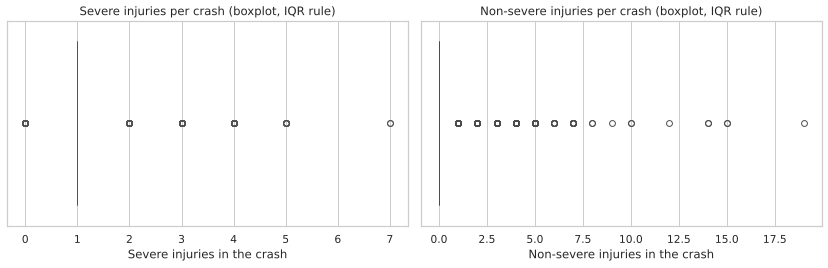

In [20]:
def iqr_bounds(series, factor=1.5):
    q1, q3 = series.quantile([0.25, 0.75])
    spread = q3 - q1
    return q1 - factor * spread, q3 + factor * spread

lower, upper = iqr_bounds(df["severe_count"])
df["is_outlier_severe"] = df["severe_count"] > upper
print(f"IQR bounds for severe injuries per crash: [{lower:.1f}, {upper:.1f}] -> "
      f"{df['is_outlier_severe'].sum():,} flagged crashes ({df['is_outlier_severe'].mean():.2%}).")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=df["severe_count"], ax=axes[0], color="#C44E52")
axes[0].set_title("Severe injuries per crash (boxplot, IQR rule)")
axes[0].set_xlabel("Severe injuries in the crash")
sns.boxplot(x=df["non_severe_count"].dropna(), ax=axes[1], color="#4C72B0")
axes[1].set_title("Non-severe injuries per crash (boxplot, IQR rule)")
axes[1].set_xlabel("Non-severe injuries in the crash")
plt.tight_layout()
plt.show()

## 5. Validation of the cleaning (before vs. after)
These checks and plots demonstrate that the cleaning did what we intended.

In [21]:
checks = pd.DataFrame({
    "rows": [len(df_raw), len(df)],
    "missing_zip": [df_raw[[c for c in df_raw.columns if 'zip' in c.lower()][0]].isna().sum(), df["zip_code"].isna().sum()],
    "duplicated_collision_ids": [df_raw.duplicated(subset=[df_raw.columns[0]]).sum(), df.duplicated(subset=[COL['collision_id']]).sum()],
}, index=["raw", "clean"])
display(checks)

assert df["zip_code"].str.fullmatch(r"\d{5}").all(), "ZIP must be a 5-digit string"
assert df["borough"].isin(VALID_BOROUGHS).all(), "borough labels must be standardized"
assert (df[["severe_count"]] >= 0).all().all(), "negative counts found"
assert df["latitude"].dropna().between(40.45, 40.95).all()
print("All validation assertions passed.")

,rows,missing_zip,duplicated_collision_ids
raw,13754,5682,444
clean,10561,0,0


All validation assertions passed.


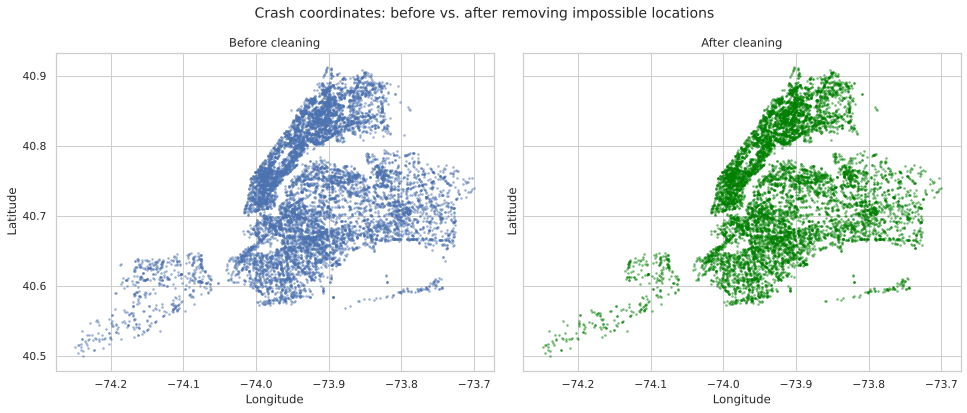

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)
axes[0].scatter(pd.to_numeric(df_raw[[c for c in df_raw.columns if 'longitude' in c.lower()][0]], errors="coerce"),
                pd.to_numeric(df_raw[[c for c in df_raw.columns if 'latitude' in c.lower()][0]], errors="coerce"), s=3, alpha=0.4)
axes[0].set_title("Before cleaning")
axes[1].scatter(df["longitude"], df["latitude"], s=3, alpha=0.4, color="green")
axes[1].set_title("After cleaning")
for ax in axes:
    ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
fig.suptitle("Crash coordinates: before vs. after removing impossible locations")
plt.tight_layout()
plt.show()

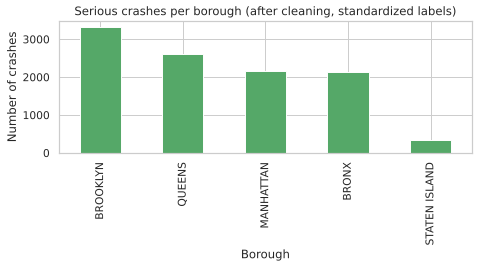

In [23]:
borough_after = df["borough"].value_counts()
fig, ax = plt.subplots(figsize=(7, 4))
borough_after.plot.bar(ax=ax, color="#55A868")
ax.set_title("Serious crashes per borough (after cleaning, standardized labels)")
ax.set_xlabel("Borough"); ax.set_ylabel("Number of crashes")
plt.tight_layout(); plt.show()

## 6. Aggregation to the integration level: ZIP code × year

**Why ZIP × year?** The housing dataset (building filings/permits) and SIRTA (crashes) do not share record identifiers, so a record-level join is meaningless. Both do contain a ZIP code and a date. Aggregating to **ZIP × year**:
- gives a stable unit (many crashes/filings per cell),
- is fine enough to see neighborhood differences (unlike borough),
- lets us study **time-lagged relationships** (housing activity in year *t* vs. crashes in year *t*/*t+1*).

**Output columns (data contract with Member 3):**

| Column | Meaning |
|---|---|
| `zip_code` | 5-digit string, join key |
| `year` | integer, join key |
| `borough` | UPPERCASE, dominant borough of the ZIP |
| `crash_count` | number of serious crashes |
| `severe_injuries_total` | sum of severe injuries |
| `non_severe_injuries_total` | sum of non-severe injuries |
| `fatalities_total` | sum of fatalities |
| `fatal_crash_count` | crashes with ≥ 1 fatality |
| `severe_per_crash` | mean severe injuries per crash |
| `night_crash_share` | share of crashes at night |
| `avg_latitude`, `avg_longitude` | centroid of the ZIP's crashes (for maps) |
| `is_outlier_zip_year` | IQR flag on `crash_count` |

In [24]:
def aggregate_to_zip_year(frame):
    frame = frame.copy()
    frame["is_fatal_crash"] = (frame["fatalities_count"].fillna(0) > 0).astype(int)
    frame["is_night"] = (frame["time_of_day"] == "night").astype(int)
    aggregated = (frame.groupby(["zip_code", "year"])
        .agg(borough=("borough", lambda s: s.mode().iloc[0]),
             crash_count=("severe_count", "size"),
             severe_injuries_total=("severe_count", "sum"),
             non_severe_injuries_total=("non_severe_count", "sum"),
             fatalities_total=("fatalities_count", "sum"),
             fatal_crash_count=("is_fatal_crash", "sum"),
             severe_per_crash=("severe_count", "mean"),
             night_crash_share=("is_night", "mean"),
             avg_latitude=("latitude", "mean"),
             avg_longitude=("longitude", "mean"))
        .reset_index())
    low, high = iqr_bounds(aggregated["crash_count"])
    aggregated["is_outlier_zip_year"] = aggregated["crash_count"] > high
    aggregated["zip_code"] = aggregated["zip_code"].astype(str)   # plain text key for the merge
    return aggregated

df_transport_agg = aggregate_to_zip_year(df)
print(df_transport_agg.shape)
df_transport_agg.head()

(703, 13)


,zip_code,year,borough,crash_count,severe_injuries_total,non_severe_injuries_total,fatalities_total,fatal_crash_count,severe_per_crash,night_crash_share,avg_latitude,avg_longitude,is_outlier_zip_year
0,10001,2022,MANHATTAN,18,19.0,4.0,1.0,1,1.055556,0.166667,40.750281,-73.995976,False
1,10001,2023,MANHATTAN,26,24.0,9.0,2.0,2,0.923077,0.307692,40.751362,-73.996973,False
2,10001,2024,MANHATTAN,21,24.0,18.0,0.0,0,1.142857,0.333333,40.750665,-73.994919,False
3,10001,2025,MANHATTAN,18,17.0,3.0,1.0,1,0.944444,0.222222,40.750087,-73.995602,False
4,10002,2022,MANHATTAN,26,31.0,4.0,2.0,2,1.192308,0.615385,40.716346,-73.986027,False


In [25]:
# Final quality checks on the aggregated table
assert not df_transport_agg.duplicated(subset=["zip_code", "year"]).any(), "key must be unique"
assert pd.api.types.is_string_dtype(df_transport_agg["zip_code"]), "ZIP must be text"
print(df_transport_agg.isna().sum()[lambda s: s > 0])
display(df_transport_agg.describe().T)

avg_latitude     3
avg_longitude    3
dtype: int64


,count,mean,std,min,25%,50%,75%,max
year,703.0,2023.512091,1.116853,2022.000000,2023.000000,2024.000000,2025.000000,2025.000000
crash_count,703.0,15.022760,10.138755,1.000000,7.000000,13.000000,22.000000,48.000000
severe_injuries_total,703.0,15.365576,10.619088,0.000000,7.000000,14.000000,22.000000,51.000000
non_severe_injuries_total,703.0,3.910384,4.317089,0.000000,1.000000,3.000000,6.000000,35.000000
fatalities_total,703.0,0.916074,1.153496,0.000000,0.000000,1.000000,1.000000,8.000000
fatal_crash_count,703.0,0.877667,1.094846,0.000000,0.000000,1.000000,1.000000,8.000000
severe_per_crash,703.0,1.016929,0.148060,0.000000,0.961538,1.000000,1.062500,2.000000
night_crash_share,703.0,0.242866,0.181935,0.000000,0.125000,0.230769,0.333333,1.000000
avg_latitude,700.0,40.727220,0.081603,40.499672,40.674457,40.726969,40.776092,40.905485
avg_longitude,700.0,-73.915767,0.096428,-74.242513,-73.977626,-73.923763,-73.847624,-73.702736


In [26]:
# Export for Member 3 (integration) and for the website
EXPORT_COLUMNS = [COL["collision_id"], "crash_date", "year", "month", "day_of_week", "crash_hour", "time_of_day",
                  "borough", "zip_code", "latitude", "longitude", "severe_count", "non_severe_count",
                  "fatalities_count", "is_outlier_severe", "on_street", "cross_street", COL["precinct"]]
df_clean_export = df[[c for c in EXPORT_COLUMNS if c in df.columns]].copy()   # only the clean, renamed columns
df_clean_export.to_csv(OUTPUT_ROW_LEVEL, index=False)
df_transport_agg.to_csv(OUTPUT_AGGREGATED, index=False)
print(f"Saved {OUTPUT_ROW_LEVEL} ({len(df_clean_export):,} rows) and {OUTPUT_AGGREGATED} ({len(df_transport_agg):,} rows).")

Saved transport_clean_row_level.csv (10,561 rows) and transport_clean.csv (703 rows).


## 7. Research questions and visualizations (Member 2)

Each question investigates a relationship **between the two domains** and is supported by exactly one chart. The charts need the integrated table from Member 3 (`df_merged`, one row per ZIP × year, containing the housing columns). The housing metric names below (`new_units`) are placeholders – rename them to the final column names agreed with the team.

**RQ1.** Do ZIP codes that receive more new residential units in year *t* experience more serious-injury crashes per year in *t* and *t+1*? *(scatter plot: housing units vs. severe injuries, colored by borough)*

**RQ2.** Is the share of **fatal and nighttime** crashes higher in boroughs/years with more residential development, or is the effect only in the *volume* of crashes? *(heatmap: borough × year, colored by severe injuries per 1,000 new units)*

> **Interpretation caution:** these are associations at ZIP level. More housing usually means more people and traffic, so crash counts rise with population; we therefore also use *rates per 1,000 new units* and do **not** claim causation.

In [27]:
# Run this cell AFTER Member 3 provides the integrated dataset (path agreed with the team).
MERGED_PATH = "integrated_dataset.csv"        # placeholder name
HOUSING_METRIC = "new_units"                  # placeholder: rename to the agreed housing column

if os.path.exists(MERGED_PATH):
    df_merged = pd.read_csv(MERGED_PATH, dtype={"zip_code": str})

    # ---------- RQ1: scatter ----------
    import plotly.express as px
    fig1 = px.scatter(
        df_merged, x=HOUSING_METRIC, y="severe_injuries_total", color="borough",
        hover_data=["zip_code", "year"], trendline="ols", log_x=True,
        title="RQ1: New residential units vs. severe injuries per ZIP code and year",
        labels={HOUSING_METRIC: "New residential units (log scale)",
                "severe_injuries_total": "Severe injuries (count)"})
    fig1.show()

    # ---------- RQ2: heatmap ----------
    pivot = (df_merged.groupby(["borough", "year"])
             .apply(lambda g: 1000 * g["severe_injuries_total"].sum() / max(g[HOUSING_METRIC].sum(), 1))
             .unstack("year"))
    fig, ax = plt.subplots(figsize=(8, 4))
    sns.heatmap(pivot, annot=True, fmt=".1f", cmap="Reds", ax=ax)
    ax.set_title("RQ2: Severe injuries per 1,000 new housing units (borough x year)")
    ax.set_xlabel("Year"); ax.set_ylabel("Borough")
    plt.tight_layout(); plt.show()
else:
    print("Integrated dataset not available yet - run this cell after the integration step.")

Integrated dataset not available yet - run this cell after the integration step.


**What to write after running (key finding, limits):** state the direction/strength of the relationship, whether it holds across boroughs, and the limitations: SIRTA contains only *serious* crashes, severity labels lag, ZIP is a coarse unit, population/traffic exposure is not controlled, and association ≠ causation.

## 8. Prompts used, links, and contribution

### 8.1 Dataset links
- **Transportation (T4, SIRTA):** https://data.cityofnewyork.us/Transportation/Serious-Injury-Response-Tracking-Analysis-Program-/xeqp-qz8h
- **Housing (Member 1):** *add the link of the chosen housing dataset here*
- **Dataset catalog / project description:** provided by the course (Dr. Nada Sharaf, TAs).

### 8.2 Prompts used (required by the project)
Record **every** prompt used in this part, with the step it supported:

| # | Step | Prompt (summary) |
|---|---|---|
| 1 | Planning | Asked an AI assistant to review the 5-member task division and timeline against the project requirements. |
| 2 | Dataset choice | Asked which transportation dataset from the catalog best integrates with a housing dataset (ZIP × year); chose T4/SIRTA (`xeqp-qz8h`). |
| 3 | Loading | Asked for code to download the dataset with the NYC Open Data API (`$limit`, `$order`) and a fallback to a local CSV. |
| 4 | Notebook | Asked an AI assistant to build the Member 2 notebook (overview, EDA, pre-integration cleaning, aggregation, research questions) using the SIRTA data dictionary, satisfying every grading requirement. |

*(Add any later prompts here, e.g. for debugging or chart design.)*

### 8.3 Member 2 contribution (copy to the README)
- Selected and documented the transportation dataset (SIRTA, T4) and justified the choice.
- Performed EDA (structure, missing values, duplicates, inconsistencies, distributions).
- Pre-integration cleaning: duplicates, format standardization (dates, borough, 5-digit ZIP), domain-rule checks, ZIP recovery from coordinates, outlier flagging (IQR), validation plots.
- Aggregated the data to ZIP × year and delivered `transport_clean.csv` per the data contract.
- Proposed 2 research questions and 2 visualizations (Section 7).